In [ ]:
##APP LINK: https://student-performance-prediction-aetbkygthvachvfnedwgqw.streamlit.app/#student-performance-prediction-system
##GITHUB: https://github.com/fa24-bed-061-svg/Student-Performance-Prediction/tree/main
##APP: STUDENT ERFORMANCE PREDICTOR

In [ ]:

import pandas as pd

df = pd.read_csv("student-mat.csv", sep=";")

display(df.head())

print("Dataset shape:", df.shape)
print("Column names:", df.columns.tolist())


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


Dataset shape: (395, 33)
Column names: ['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']


In [ ]:

print("Missing values in each column:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())
print("\nDataset information:")
df.info()
print("\nFinal Grade (G3) statistics:")
print(df["G3"].describe())


Missing values in each column:
school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

Duplicate rows: 0

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5

In [ ]:

from sklearn.model_selection import KFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import make_scorer, mean_squared_error
from sklearn.tree import ExtraTreeRegressor
from sklearn.ensemble import (
    AdaBoostRegressor,
    HistGradientBoostingRegressor,
    ExtraTreesRegressor,
    RandomForestRegressor
)
from sklearn.linear_model import Ridge
from sklearn.compose import TransformedTargetRegressor
import numpy as np

# Separate features and target
X = df.drop(columns=["G3"])
y = df["G3"]

# Identify numeric and categorical columns
numeric_cols = X.select_dtypes(include=["int64", "float64"]).columns
categorical_cols = X.select_dtypes(include=["object"]).columns

# Preprocess numeric and categorical data
preprocessor = ColumnTransformer([
    ("numeric", SimpleImputer(strategy="median"), numeric_cols),
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_cols)
])

# Define 5 algorithms not used in the Car Price notebook
models = {
    "Ridge Regression": Ridge(),
    "Extra Tree": ExtraTreeRegressor(random_state=42),
    "AdaBoost": AdaBoostRegressor(random_state=42),
    "Extra Trees": ExtraTreesRegressor(n_estimators=100, random_state=42),
    "Hist Gradient Boosting": HistGradientBoostingRegressor(random_state=42)
}

print("Features:", X.shape)
print("Target:", y.shape)
print("Algorithms selected:", len(models))
print("10-Fold Cross-Validation setup ready.")


Features: (395, 32)
Target: (395,)
Algorithms selected: 5
10-Fold Cross-Validation setup ready.


In [ ]:

# Set up 10-Fold Cross-Validation
cv = KFold(n_splits=10, shuffle=True, random_state=42)

# Store model comparison results
results = []

# Evaluate all 5 algorithms
for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", model)
    ])

    scores = cross_validate(
        pipeline,
        X,
        y,
        cv=cv,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1
    )

    rmse_scores = -scores["test_score"]

    results.append({
        "Algorithm": name,
        "Mean RMSE": rmse_scores.mean(),
        "Std RMSE": rmse_scores.std()
    })

# Create comparison table
results_df = pd.DataFrame(results)
results_df = results_df.sort_values("Mean RMSE")

display(results_df.round(3))

# Best-performing algorithm
best_model_name = results_df.iloc[0]["Algorithm"]
print("Best algorithm based on mean RMSE:", best_model_name)


,Algorithm,Mean RMSE,Std RMSE
4,Hist Gradient Boosting,1.585,0.452
2,AdaBoost,1.726,0.400
3,Extra Trees,1.857,0.428
0,Ridge Regression,2.017,0.284
1,Extra Tree,2.712,0.312


Best algorithm based on mean RMSE: Hist Gradient Boosting


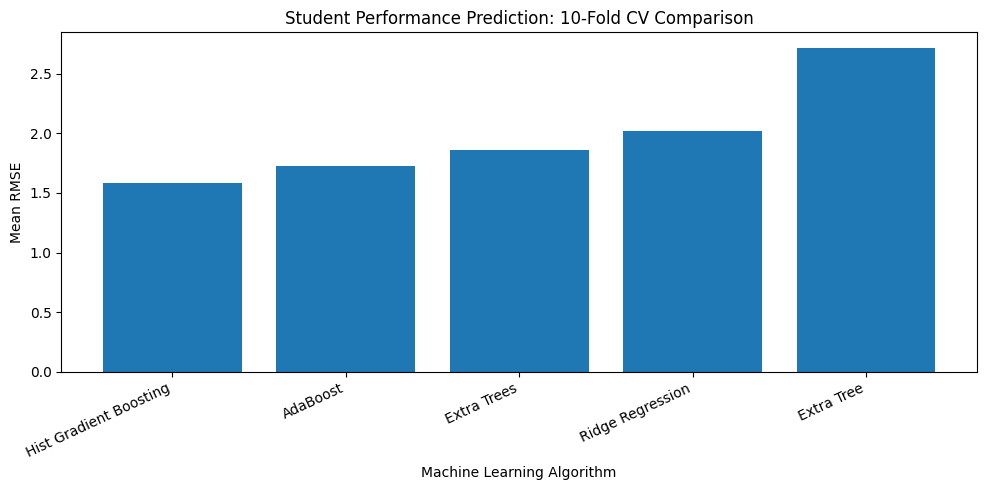

In [ ]:

import matplotlib.pyplot as plt

# Plot model comparison
plt.figure(figsize=(10, 5))
plt.bar(results_df["Algorithm"], results_df["Mean RMSE"])
plt.xlabel("Machine Learning Algorithm")
plt.ylabel("Mean RMSE")
plt.title("Student Performance Prediction: 10-Fold CV Comparison")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()


In [ ]:

import joblib
from sklearn.pipeline import Pipeline
from sklearn.ensemble import HistGradientBoostingRegressor

# Create the best model pipeline
best_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", HistGradientBoostingRegressor(random_state=42))
])

# Train on the full dataset for deployment
best_pipeline.fit(X, y)

# Save the trained model
joblib.dump(best_pipeline, "student_performance_model.pkl")

print("Best model trained and saved successfully!")


Best model trained and saved successfully!


In [ ]:
from google.colab import files
files.download("student_performance_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [9]:
import sklearn
import numpy
import pandas

print("Scikit-learn:", sklearn.__version__)
print("NumPy:", numpy.__version__)
print("Pandas:", pandas.__version__)

Scikit-learn: 1.6.1
NumPy: 2.1.3
Pandas: 2.2.3


In [10]:

import joblib
import sklearn
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.ensemble import HistGradientBoostingRegressor

print("Scikit-learn version:", sklearn.__version__)

best_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", HistGradientBoostingRegressor(random_state=42))
])

best_pipeline.fit(X, y)

joblib.dump(best_pipeline, "student_performance_model.pkl")

print("Model retrained and saved successfully!")


Scikit-learn version: 1.6.1
Model retrained and saved successfully!


In [11]:

from google.colab import files
files.download("student_performance_model.pkl")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>